# 03 — EDA IEEE-CIS

Data transaksi kartu dari Vesta (kompetisi Kaggle 2019). Berbeda dari PaySim, ini **data nyata** yang disamarkan: nama sebagian besar kolom ditutup, dan tidak ada ID pengguna.

Strategi (dari diskusi): pelajari kolom **per kelompok**, bukan satu per satu; potong data **berdasarkan waktu**; pilih fitur hanya dengan **data latih**.

| # | Pertanyaan | Keputusan yang bergantung padanya |
|---|---|---|
| 1 | Bagaimana fraud tersebar dalam waktu? | Titik potong train/validasi/test |
| 2 | Kelompok kolom mana yang banyak kosong, dan apakah kosongnya berpola? | Kolom mana yang dipakai/diringkas |
| 3 | Kolom kategori mana yang membedakan fraud? | Fitur dasar |
| 4 | Bisakah kita mengenali "orang yang sama" tanpa ID pengguna? | Fitur perilaku |

Seperti notebook 01, isi kotak **🧠 Keputusanmu** sebelum lanjut.

In [1]:
import sys, pathlib, time
ROOT = pathlib.Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.max_columns', 60)
RAW = ROOT / 'data/raw/ieee-cis'
PARQUET = ROOT / 'data/processed/ieee_train.parquet'

## 0. Muat data
Dua file digabung lewat `TransactionID`: `train_transaction` (semua transaksi) dan `train_identity` (info perangkat/jaringan, **hanya untuk sebagian transaksi**).

Hampir 400 kolom × 590 ribu baris bisa memakan beberapa GB RAM. Angka disimpan sebagai `float32` dan teks sebagai `category` supaya hemat, lalu disimpan ke parquet agar pembacaan berikutnya cepat.

In [2]:
TEXT_TX = ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain'] + [f'M{i}' for i in range(1, 10)]

def load_raw():
    cols = pd.read_csv(RAW / 'train_transaction.csv', nrows=0).columns
    dtypes = {c: ('category' if c in TEXT_TX else 'float32') for c in cols}
    dtypes.update(TransactionID='int32', isFraud='int8', TransactionDT='int32')
    tx = pd.read_csv(RAW / 'train_transaction.csv', dtype=dtypes)
    idt = pd.read_csv(RAW / 'train_identity.csv')
    for c in idt.columns:
        if c == 'TransactionID':
            continue
        if pd.api.types.is_numeric_dtype(idt[c]):
            idt[c] = idt[c].astype('float32')
        else:                                   # teks (object/str, tergantung versi pandas)
            idt[c] = idt[c].astype('category')
    df = tx.merge(idt, on='TransactionID', how='left')
    df['has_identity'] = df.TransactionID.isin(idt.TransactionID).astype('int8')
    return df.sort_values('TransactionDT').reset_index(drop=True)

t0 = time.time()
if PARQUET.exists():
    df = pd.read_parquet(PARQUET)
else:
    df = load_raw()
    PARQUET.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(PARQUET, index=False)
print(f"{df.shape[0]:,} baris × {df.shape[1]} kolom, {time.time() - t0:.0f} detik, "
      f"memori {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Tingkat fraud: {df.isFraud.mean():.2%} ({df.isFraud.sum():,} kasus)")
print(f"Punya data identitas: {df.has_identity.mean():.1%} transaksi")

C:\Users\Haikal\AppData\Local\Temp\ipykernel_13236\2150830453.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['has_identity'] = df.TransactionID.isin(idt.TransactionID).astype('int8')


590,540 baris × 435 kolom, 21 detik, memori 0.97 GB
Tingkat fraud: 3.50% (20,663 kasus)
Punya data identitas: 24.4% transaksi


## 1. Waktu
`TransactionDT` = jumlah **detik** sejak suatu titik awal yang dirahasiakan (bukan tanggal). Kita ubah ke **hari ke-berapa** supaya mudah dibaca, sama seperti `step` di PaySim.

C:\Users\Haikal\AppData\Local\Temp\ipykernel_13236\2889358392.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['day'] = (df.TransactionDT // 86400).astype('int16')


Rentang: hari 1 sampai 182 (~6.0 bulan)


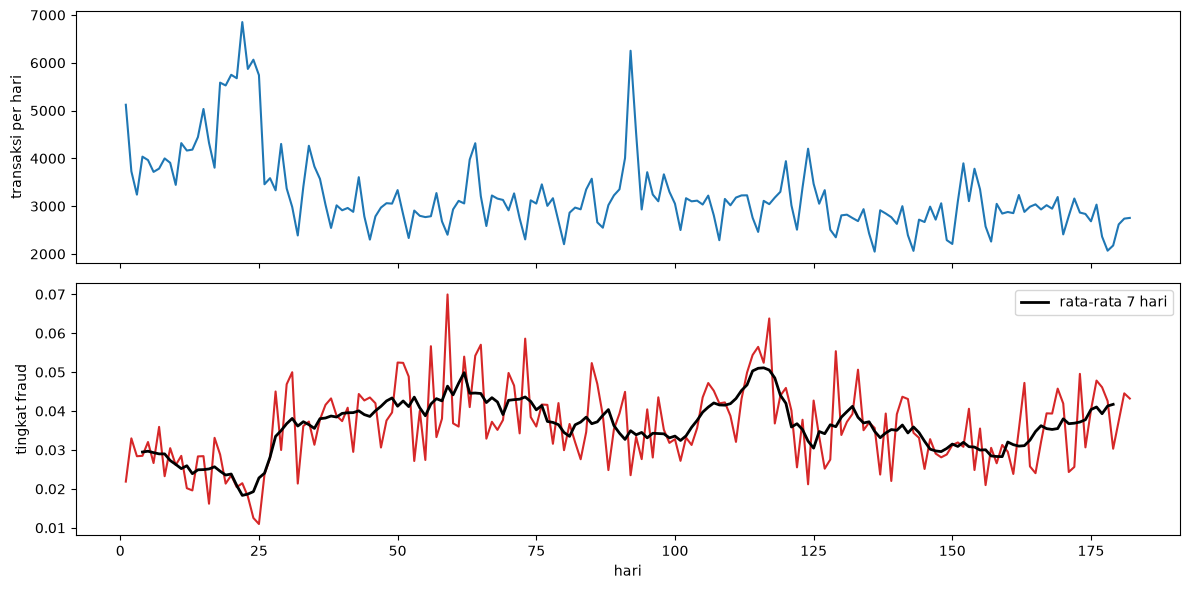

In [3]:
df['day'] = (df.TransactionDT // 86400).astype('int16')
print(f"Rentang: hari {df.day.min()} sampai {df.day.max()} (~{(df.day.max() - df.day.min()) / 30:.1f} bulan)")

daily = df.groupby('day').agg(n=('isFraud', 'size'), fraud_rate=('isFraud', 'mean'))
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(daily.index, daily.n); ax[0].set_ylabel('transaksi per hari')
ax[1].plot(daily.index, daily.fraud_rate, color='C3'); ax[1].set_ylabel('tingkat fraud')
ax[1].plot(daily.index, daily.fraud_rate.rolling(7, center=True).mean(), color='k', lw=2, label='rata-rata 7 hari')
ax[1].legend(); ax[1].set_xlabel('hari'); plt.tight_layout(); plt.show()

In [4]:
cum = daily.n.cumsum() / daily.n.sum()
for q in [0.6, 0.7, 0.8, 0.9]:
    d = int((cum >= q).idxmax())
    print(f"{q:.0%} transaksi tercapai di hari {d:>3} | tingkat fraud s/d hari itu: "
          f"{df[df.day <= d].isFraud.mean():.2%}, sesudahnya: {df[df.day > d].isFraud.mean():.2%}")

60% transaksi tercapai di hari 101 | tingkat fraud s/d hari itu: 3.38%, sesudahnya: 3.68%
70% transaksi tercapai di hari 120 | tingkat fraud s/d hari itu: 3.52%, sesudahnya: 3.44%
80% transaksi tercapai di hari 141 | tingkat fraud s/d hari itu: 3.52%, sesudahnya: 3.41%
90% transaksi tercapai di hari 161 | tingkat fraud s/d hari itu: 3.47%, sesudahnya: 3.76%


> **🧠 Keputusanmu:** Bandingkan dengan PaySim (volume anjlok setelah step 400, tingkat fraud melonjak 12×).
> - Apakah volume dan tingkat fraud di IEEE-CIS cukup **stabil** dari waktu ke waktu?
> - Berdasarkan grafik, pembagian 70/15/15 **berurutan waktu** berdasarkan jumlah baris sudah cukup, atau perlu penanganan khusus seperti opsi A di PaySim?
>
> _Jawaban:_
> volume dan tingkat fraud cukup stabil tapi ada beberapa lonjakan dan penurunan sampai sedikit tingkat fraudnya
> mungkin tidak perlu penanganan khusus

## 2. Kelompok kolom dan pola kekosongan

In [5]:
import re
def group_of(c):
    m = re.match(r'^(card|addr|dist|C|D|M|V|id_)\d*', c)
    if c in ('P_emaildomain', 'R_emaildomain'): return 'email'
    if c in ('DeviceType', 'DeviceInfo'): return 'device'
    return m.group(1) if m else None

groups = {}
for c in df.columns:
    g = group_of(c)
    if g: groups.setdefault(g, []).append(c)

miss = df.isna().mean()
summary = pd.DataFrame({
    'jumlah_kolom': {g: len(cs) for g, cs in groups.items()},
    'kosong_min': {g: miss[cs].min() for g, cs in groups.items()},
    'kosong_median': {g: miss[cs].median() for g, cs in groups.items()},
    'kosong_maks': {g: miss[cs].max() for g, cs in groups.items()},
}).sort_values('jumlah_kolom', ascending=False)
summary

,jumlah_kolom,kosong_min,kosong_median,kosong_maks
V,339,0.0000,0.4729,0.8612
id_,38,0.7558,0.8244,0.9920
D,15,0.0021,0.5247,0.9341
C,14,0.0000,0.0000,0.0000
M,9,0.2868,0.4766,0.5935
card,6,0.0000,0.0027,0.0151
addr,2,0.1113,0.1113,0.1113
email,2,0.1599,0.4637,0.7675
dist,2,0.5965,0.7664,0.9363
device,2,0.7616,0.7803,0.7991


**Blok kekosongan di kolom V.** Kolom yang kosong di **baris yang persis sama** kemungkinan berasal dari sumber yang sama. Kita kelompokkan kolom V berdasarkan pola kosongnya.

In [6]:
vcols = groups['V']
pattern = {c: hash(df[c].isna().to_numpy().tobytes()) for c in vcols}
blocks = pd.Series(pattern).groupby(lambda c: pattern[c]).apply(lambda s: list(s.index))
blocks = sorted(blocks, key=lambda b: int(b[0][1:]))
print(f"{len(vcols)} kolom V terbagi ke {len(blocks)} blok pola kekosongan\n")
for b in blocks[:15]:
    print(f"  {b[0]:>5} … {b[-1]:<5} ({len(b):>3} kolom)  kosong {miss[b[0]]:.1%}")

339 kolom V terbagi ke 15 blok pola kekosongan

     V1 … V11   ( 11 kolom)  kosong 47.3%
    V12 … V34   ( 23 kolom)  kosong 12.9%
    V35 … V52   ( 18 kolom)  kosong 28.6%
    V53 … V74   ( 22 kolom)  kosong 13.1%
    V75 … V94   ( 20 kolom)  kosong 15.1%
    V95 … V137  ( 43 kolom)  kosong 0.1%
   V138 … V163  ( 18 kolom)  kosong 86.1%
   V143 … V166  ( 11 kolom)  kosong 86.1%
   V167 … V216  ( 31 kolom)  kosong 76.4%
   V169 … V210  ( 19 kolom)  kosong 76.3%
   V217 … V278  ( 46 kolom)  kosong 77.9%
   V220 … V272  ( 16 kolom)  kosong 76.1%
   V279 … V321  ( 32 kolom)  kosong 0.0%
   V281 … V315  ( 11 kolom)  kosong 0.2%
   V322 … V339  ( 18 kolom)  kosong 86.1%


In [7]:
# Seberapa mirip isi kolom di dalam SATU blok? Ambil blok terbesar sebagai contoh.
big = max(blocks, key=len)
sample = df[big].sample(min(50_000, len(df)), random_state=0)  # sampel: korelasi tidak butuh semua baris
corr = sample.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print(f"Blok {big[0]}…{big[-1]} ({len(big)} kolom): "
      f"{(upper > 0.95).sum().sum()} pasang kolom berkorelasi > 0,95")

Blok V217…V278 (46 kolom): 23 pasang kolom berkorelasi > 0,95


> **🧠 Keputusanmu:**
> - Banyak kolom V berkorelasi sangat tinggi di dalam bloknya. Apa untungnya membuang sebagian, kalau XGBoost toh bisa memproses semua kolom? (Pikirkan: kecepatan scoring real-time, memori, dan penjelasan model.)
> - Bagaimana cara memilih **wakil** dari tiap blok? Ingat: pemilihan hanya boleh memakai data latih.
>
> _Jawaban:_
> membuang sebagian dapan mempercepat scoring real time dan model tidak kesulitan karena tiap bloknya berkorelasi
> mungkin yg korelasinya paling tinggi

## 3. Kolom kategori

In [8]:
def fraud_by(col, top=10):
    t = df.groupby(col, observed=True, dropna=False).isFraud.agg(n='size', fraud_rate='mean')
    return t.sort_values('n', ascending=False).head(top)

for col in ['ProductCD', 'card4', 'card6', 'DeviceType', 'has_identity']:
    print(f"\n— {col}"); print(fraud_by(col))


— ProductCD
                n  fraud_rate
ProductCD                    
W          439670      0.0204
C           68519      0.1169
R           37699      0.0378
H           33024      0.0477
S           11628      0.0590

— card4
                       n  fraud_rate
card4                               
visa              384767      0.0348
mastercard        189217      0.0343
american express    8328      0.0287
discover            6651      0.0773
NaN                 1577      0.0260

— card6
                      n  fraud_rate
card6                              
debit            439938      0.0243
credit           148986      0.0668
NaN                1571      0.0248
debit or credit      30      0.0000
charge card          15      0.0000

— DeviceType
                 n  fraud_rate
DeviceType                    
NaN         449730      0.0210
desktop      85165      0.0652
mobile       55645      0.1017

— has_identity
                   n  fraud_rate
has_identity                  

In [9]:
fraud_by('P_emaildomain', top=12)

,n,fraud_rate
P_emaildomain,,
gmail.com,228355,0.0435
yahoo.com,100934,0.0228
NaN,94456,0.0295
hotmail.com,45250,0.0530
anonymous.com,36998,0.0232
aol.com,28289,0.0218
comcast.net,7888,0.0312
icloud.com,6267,0.0314
outlook.com,5096,0.0946


In [10]:
# Nominal: fraud vs normal
amt = df.groupby('isFraud').TransactionAmt.describe(percentiles=[.1, .5, .9, .99])
amt

,count,mean,std,min,10%,50%,90%,99%,max
isFraud,,,,,,,,,
0,"569,877.0000",134.5117,239.3951,0.2510,26.3100,68.5000,267.1120,"1,104.0000","31,937.3906"
1,"20,663.0000",149.2448,232.2122,0.2920,18.9360,75.0000,335.0000,994.0000,"5,191.0000"


> **🧠 Keputusanmu:** Kategori mana yang tingkat fraud-nya jauh dari rata-rata (≈3,5%)? Apakah itu sinyal nyata, atau bisa saja kebetulan karena jumlah transaksinya kecil? Kolom `n` membantu menilainya.
>
> _Jawaban:_
> productCD = C, card = discover, hasidentity = 1, email = outlook.com. ada yg jumlah transaksinya sedikit tapi untuk product c transaksinya besar

## 4. Mengenali "orang yang sama" tanpa ID pengguna
Fitur perilaku butuh ID. IEEE-CIS tidak punya, tetapi ada petunjuk:
- `card1`–`card6`: ciri kartu (yang sama untuk satu kartu)
- `addr1`: alamat penagihan (disamarkan)
- `D1`: dari keterangan penyelenggara, berkaitan dengan **jumlah hari sejak** suatu kejadian pada kartu/akun

In [11]:
print(f"card1 unik: {df.card1.nunique():,} untuk {len(df):,} transaksi")
per_card = df.groupby('card1').size()
print("Transaksi per card1:"); print(per_card.describe(percentiles=[.5, .9, .99]))

card1 unik: 13,553 untuk 590,540 transaksi
Transaksi per card1:
count   13,553.0000
mean        43.5726
std        329.0845
min          1.0000
50%          4.0000
90%         46.0000
99%        786.4400
max     14,932.0000
dtype: float64


In [12]:
# Eksperimen: kalau D1 = 'hari sejak kartu/akun dibuka', maka (day - D1) = tanggal pembukaan,
# yang SAMA untuk semua transaksi milik orang yang sama.
df['D1n'] = df.day - df.D1
top_card = per_card.idxmax()
sub = df[df.card1 == top_card]
print(f"card1 = {top_card}: {len(sub):,} transaksi")
print(f"  kombinasi (card1, addr1) unik     : {sub.groupby(['addr1'], dropna=False).ngroups:,}")
print(f"  kombinasi (card1, addr1, D1n) unik: {sub.groupby(['addr1', 'D1n'], dropna=False).ngroups:,}")

card1 = 7919.0: 14,932 transaksi
  kombinasi (card1, addr1) unik     : 58
  kombinasi (card1, addr1, D1n) unik: 3,753


C:\Users\Haikal\AppData\Local\Temp\ipykernel_13236\2186418452.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['D1n'] = df.day - df.D1


In [13]:
uid = df.card1.astype(str) + '_' + df.addr1.astype(str) + '_' + df.D1n.astype(str)
per_uid = uid.value_counts()
print(f"Kandidat ID (card1 + addr1 + D1n): {per_uid.size:,} unik")
print(f"  rata-rata transaksi per ID: {per_uid.mean():.1f}, median: {per_uid.median():.0f}")
# Apakah fraud 'menular' di dalam satu kandidat ID?
g = df.assign(uid=uid).groupby('uid').isFraud.agg(['size', 'mean'])
multi = g[g['size'] >= 2]
print(f"  ID dengan ≥2 transaksi yang punya fraud: tingkat fraud rata-rata di dalamnya "
      f"{multi[multi['mean'] > 0]['mean'].mean():.0%}")

Kandidat ID (card1 + addr1 + D1n): 199,070 unik
  rata-rata transaksi per ID: 2.6, median: 1


C:\Users\Haikal\AppData\Local\Temp\ipykernel_13236\2495915163.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = df.assign(uid=uid).groupby('uid').isFraud.agg(['size', 'mean'])


  ID dengan ≥2 transaksi yang punya fraud: tingkat fraud rata-rata di dalamnya 73%


> **🧠 Keputusanmu:**
> - Apakah kombinasi `card1 + addr1 + D1n` tampak seperti ID orang? Apa buktinya, dan apa risikonya kalau tebakan ini salah?
> - Kalau satu ID pernah melakukan fraud, transaksi lain dari ID yang sama cenderung fraud juga. Fitur apa yang bisa memanfaatkan ini **tanpa menyontek** label masa depan? (Ingat: label di produksi datang berminggu-minggu kemudian.)
>
> _Jawaban:_
> ya karena jumlah uniknya cukup banyak. kalau salah model akan salah menginterpretasikan padahal beda pemilik kartu
> fitur card

## Ringkasan temuan
Isi setelah selesai, lalu salin ke `docs/keputusan.md`.

- Pola waktu & titik potong:
- Kelompok kolom & blok V:
- Kategori yang menonjol:
- Kandidat ID pengguna: